# Preprocessing raw HLS and ERA5 data






After downloading HLS L30 and ERA5-Land $T_{2m}$ data for new cities in [download data](./4_download_data.ipynb), this notebook provides steps to preprocess this data. The preprocessing pipeline produces patches for LST targets and stacked inputs (HLS bands and ERA5 statistic layers) in Geotiff format. The image below describes the preprocessing workflow.


![preprocessing.png](attachment:preprocessing.png)

**Land Surface Temperature (LST)**

LST is computed using B04, B05, B10 and B11 from the Landsat OLI(8) acquisitions, following a split-window algorithm.

Relevant literature:
* Du C, Ren H, Qin Q, Meng J, Zhao S. A Practical Split-Window Algorithm for Estimating Land Surface Temperature from Landsat 8 Data. Remote Sensing. 2015; 7(1):647-665. https://doi.org/10.3390/rs70100647

## **Producing inference datasets** <br>
Activate the environment created in the [Getting Started Notebook](./1_getting_started.ipynb)

Edit the [config file](../utils/config_preprocess.json) to consider: <br>
* cloud cover percentage of HLS images to process
* scaling of HLS bands
* output file format: patches/tiles
* percentage of allowable NaNs

**Notes:**<br>
* This is an example notebook to preprocess data for a single or multiple cities.

* We assume you have downloaded the HLS L30 and ERA5 $T_{2m}$ data in the format described in [download data](./4_download_data.ipynb)

* Stacked patches or tiles produced from this workflow include ocean masking and filtering for invalid data (clouds, negative and NaN pixels) based on the specified allowed NaN precentage "perc_nan".

* Output patches or tiles are saved with a local timestamp and will not correspond to the UTC timestamp on the raw HLS tiles. This is to ensure the correct ERA5 $T_{2m}$ statistics are computed.


Check the log files to verify any errors in the processed tiles/patches.

### **1. Stacked-tiles**
To produce full stacked tiles, edit the "stack_patch" section on [config file](../utils/config_preprocess.json) as follows:
* "output_files": "stacked-tiles"  
* "perc_nan": Set the percentage of allowed invalid pixels (float)

### **Warning**:
Depending on the number of cities and period of data downloaded, large RAM might be required to run the preprocessing cell below. Alternatively, consider preprocessing only a subset of the data.


In [ ]:
!pip install terratorch huey rasterio xarray pytorch-lightning rioxarray "torchgeo<0.8.0" utils numpy pandas

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 1.9 MB/s eta 0:00:00
INFO: pip is looking at multiple versions of terratorch to determine which version is compatible with other requirements. This could take a while.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.6/56.6 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 643.8/643.8 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 859.3/859.3 kB 12.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 10.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 37.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.4/72.4 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 43.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 605.0/605.0 kB 42.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 47.7 MB/s eta 0:00:00
   ━━━━━━━━━━━

In [ ]:
import os
import sys
from google.colab import drive


# Step 1: Mount Google Drive
# Use force_remount=True to handle cases where it's already mounted or has files.
drive.mount('/content/drive')

# Step 2: Create a workspace folder on Drive
WORKSPACE_DIR = '/content/drive/MyDrive/colab_workspace'
DATA_DIR = os.path.join(WORKSPACE_DIR, 'data')

# Only create DATA_DIR, packages will be installed globally
os.makedirs(DATA_DIR, exist_ok=True)

print("Workspace initialized.")

repo_path = '/content/drive/MyDrive/Granite_LST_Project/repo'
if not os.path.exists(repo_path):
    !git clone https://github.com/ibm-granite/granite-geospatial-land-surface-temperature.git {repo_path}
else:
    print("Repository already exists on Google Drive. Skipping clone.")

Mounted at /content/drive
Workspace initialized.
Repository already exists on Google Drive. Skipping clone.


In [ ]:
import os

import shutil



hls_dir = "/content/drive/MyDrive/colab_workspace/data/hls/amritsar_ind"
print(f" {len(os.listdir(hls_dir))}")
for folder_name in os.listdir(hls_dir):

    full_folder_path = os.path.join(hls_dir, folder_name)
    print(f"Folder: {folder_name}")

    # Check if it's actually a directory before listing contents

    if os.path.isdir(full_folder_path):

        for file_name in os.listdir(full_folder_path):

            print(f"  File: {file_name}")

    else:

        print(f"  (Not a directory, skipping file listing for {folder_name})")

 97
Folder: HLS.L30.T43RDQ.2022027T053652.v2.0
  File: HLS.L30.T43RDQ.2022027T053652.v2.0.B07.tif
  File: HLS.L30.T43RDQ.2022027T053652.v2.0.B09.tif
  File: HLS.L30.T43RDQ.2022027T053652.v2.0.B06.tif
  File: HLS.L30.T43RDQ.2022027T053652.v2.0.B03.tif
  File: HLS.L30.T43RDQ.2022027T053652.v2.0.B02.tif
  File: HLS.L30.T43RDQ.2022027T053652.v2.0.B10.tif
  File: HLS.L30.T43RDQ.2022027T053652.v2.0.B04.tif
  File: HLS.L30.T43RDQ.2022027T053652.v2.0.B05.tif
  File: HLS.L30.T43RDQ.2022027T053652.v2.0.B11.tif
  File: HLS.L30.T43RDQ.2022027T053652.v2.0.Fmask.tif
Folder: HLS.L30.T43RDQ.2022028T053033.v2.0
  File: HLS.L30.T43RDQ.2022028T053033.v2.0.B02.tif
  File: HLS.L30.T43RDQ.2022028T053033.v2.0.B09.tif
  File: HLS.L30.T43RDQ.2022028T053033.v2.0.B03.tif
  File: HLS.L30.T43RDQ.2022028T053033.v2.0.B10.tif
  File: HLS.L30.T43RDQ.2022028T053033.v2.0.B07.tif
  File: HLS.L30.T43RDQ.2022028T053033.v2.0.B11.tif
  File: HLS.L30.T43RDQ.2022028T053033.v2.0.Fmask.tif
  File: HLS.L30.T43RDQ.2022028T053033.v

In [ ]:
import os

import shutil

cities = [
    "amritsar_ind",
    "bhopal_ind",
    "bhubaneshwar_ind",
    "chandigarh_ind",
    "jamshedpur_ind",
    "jaipur_ind",
    "kochi_ind",
    "lucknow_ind",
    "nagpur_ind",
    "patna_ind",
    "raipur_ind",
    "surat_ind",
    "visakhapatnam_ind",
    "agra_ind",
    "ajmer_ind",
    "kanpur_ind",
    "mysuru_ind",
    "srinagar_ind"
]

for city in cities:
  hls_dir = f"/content/drive/MyDrive/colab_workspace/data/hls/{city}"
  if hls_dir:
        target = os.listdir(os.path.join(hls_dir, 'target-lst'))
        input = os.listdir(os.path.join(hls_dir, 'hls-predict-ready'))
        print(f"{city} : target-lst: {len(target)} hls-predict-ready: {len(input)}")
        print(f"Difference = {len(input) - len(target)}")
  else:
        print('target-lst not processed yet')


amritsar_ind : target-lst: 34 hls-predict-ready: 34
Difference = 0
bhopal_ind : target-lst: 24 hls-predict-ready: 24
Difference = 0
bhubaneshwar_ind : target-lst: 33 hls-predict-ready: 35
Difference = 2
chandigarh_ind : target-lst: 39 hls-predict-ready: 42
Difference = 3
jamshedpur_ind : target-lst: 33 hls-predict-ready: 37
Difference = 4
jaipur_ind : target-lst: 34 hls-predict-ready: 38
Difference = 4
kochi_ind : target-lst: 35 hls-predict-ready: 42
Difference = 7
lucknow_ind : target-lst: 26 hls-predict-ready: 36
Difference = 10
nagpur_ind : target-lst: 44 hls-predict-ready: 48
Difference = 4
patna_ind : target-lst: 37 hls-predict-ready: 42
Difference = 5
raipur_ind : target-lst: 38 hls-predict-ready: 43
Difference = 5
surat_ind : target-lst: 36 hls-predict-ready: 41
Difference = 5
visakhapatnam_ind : target-lst: 24 hls-predict-ready: 23
Difference = -1
agra_ind : target-lst: 40 hls-predict-ready: 46
Difference = 6
ajmer_ind : target-lst: 33 hls-predict-ready: 38
Difference = 5
kanpu

In [ ]:
# # MAIN PREPROCESSING SCRIPT FOR TARGET-LST GENERATION ONLY

# import os
# import json

# repo_path = "/content/drive/MyDrive/Granite_LST_Project/repo"
# preprocess_file = 'main_preprocess.py'
# config_file = 'config_preprocess.json'

# cities = [
#     "amritsar_ind",
#     # "bhopal_ind",
#     # "bhubaneshwar_ind",
#     # "chandigarh_ind",
#     # "jamshedpur_ind",
#     # "jaipur_ind",
#     # "kochi_ind",
#     # "lucknow_ind",
#     # "nagpur_ind",
#     # "patna_ind",
#     # "raipur_ind",
#     # "surat_ind",
#     # "visakhapatnam_ind",
#     # "agra_ind",
#     # "ajmer_ind",
#     # "kanpur_ind",
#     # "mysuru_ind",
#     # "srinagar_ind"
# ]

# preprocess_script_abs_path = os.path.join(repo_path, 'utils', preprocess_file)
# config_file_abs_path = os.path.join(repo_path, 'utils', config_file)
# base_workspace = "/content/drive/MyDrive/colab_workspace/data"

# for city in cities:
#     print(f"\n==========================================")
#     print(f"Starting Preprocessing for: {city}")
#     print(f"==========================================")

#     city_hls_save_dir = os.path.join(base_workspace, "hls", city)
#     city_era5_dir = os.path.join(base_workspace, "era5", city)

#     for subfolder in ["target-lst", "hls-bands", "fmask"]:
#         os.makedirs(os.path.join(city_hls_save_dir, subfolder), exist_ok=True)

#     with open(config_file_abs_path, 'r') as f:
#         config_data = json.load(f)

#     # ------------------------------------------------------------------
#     # KEY FIXES FOR SPEED & TARGET-LST ONLY:
#     # ------------------------------------------------------------------
#     config_data["workflow_options"]["cities"]["city_names"] = [city]
#     config_data["workflow_options"]["cities"]["data_save_dir"] = city_hls_save_dir
#     config_data["workflow_options"]["stack_patch"]["era5_dir"] = city_era5_dir

#     # 1. Set output_files to stacked-tiles (Skips patch creation & dataset splitting)
#     config_data["workflow_options"]["stack_patch"]["output_files"] = "stacked-tiles"

#     # 2. Maximize worker threads for parallel execution
#     config_data["workflow_options"]["compute"]["max_threads"] = 8

#     with open(config_file_abs_path, 'w') as f:
#         json.dump(config_data, f, indent=4)

#     print(f"Updated {config_file} for {city} (Mode: stacked-tiles)")

#     # Execute main_preprocess.py
#     !cd {repo_path}/utils && python {preprocess_script_abs_path} --configpath {config_file_abs_path}

# print("\n✅ Target LST processing complete for all active cities!")


Starting Preprocessing for: amritsar_ind
Updated config_preprocess.json for amritsar_ind (Mode: stacked-tiles)
Process ForkPoolWorker-20:
Process ForkPoolWorker-19:
Process ForkPoolWorker-23:
Process ForkPoolWorker-22:
Process ForkPoolWorker-25:
Process ForkPoolWorker-21:
Process ForkPoolWorker-24:
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
  File "/usr/lib/python3.13/multiprocessing/process.py", line 313, in _bootstrap
    self.run()
    ~~~~~~~~^^
  File "/usr/lib/python3.13/multiprocessing/process.py", line 108, in run
    self._target(*self._args, **self._kwargs)
    ~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.13/multiprocessing/pool.py", line 114, in worker
    task = get()
  File "/usr/lib/python3.13/multiprocessing/queues.py", line 384, in get
    with self._rlock:
         ^^^^^^^^^^^
  Fil

In [ ]:
# MAIN PREPROCESSING SCRIPT FOR TARGET-LST GENERATION ONLY

import os
import json

repo_path = "/content/drive/MyDrive/Granite_LST_Project/repo"
preprocess_file = 'main_preprocess.py'
config_file = 'config_preprocess.json'

cities = [
    # "amritsar_ind",
    # "bhopal_ind",
    # "bhubaneshwar_ind",
    # "chandigarh_ind",
    # "jamshedpur_ind",
    # "jaipur_ind",
    # "kochi_ind",
    # "lucknow_ind",
    # "nagpur_ind",
    # "patna_ind",
    # "raipur_ind",
    # "surat_ind",
    # "visakhapatnam_ind",
    # "agra_ind",
    # "ajmer_ind",
    "kanpur_ind",
    # "mysuru_ind",
    # "srinagar_ind"
]

preprocess_script_abs_path = os.path.join(repo_path, 'utils', preprocess_file)
config_file_abs_path = os.path.join(repo_path, 'utils', config_file)
base_workspace = "/content/drive/MyDrive/colab_workspace/data"
base_workspace2 = "/content/drive/MyDrive/colab_workspace/data_old"

for city in cities:
    print(f"\n==========================================")
    print(f"Starting Preprocessing for: {city}")
    print(f"==========================================")

    city_hls_save_dir = os.path.join(base_workspace, "hls", city)
    city_era5_dir = os.path.join(base_workspace2, "era5", city)

    for subfolder in ["target-lst", "hls-bands", "fmask"]:
        os.makedirs(os.path.join(city_hls_save_dir, subfolder), exist_ok=True)

    with open(config_file_abs_path, 'r') as f:
        config_data = json.load(f)

    # ------------------------------------------------------------------
    # KEY FIXES FOR SPEED & TARGET-LST ONLY:
    # ------------------------------------------------------------------
    config_data["workflow_options"]["cities"]["city_names"] = [city]
    config_data["workflow_options"]["cities"]["data_save_dir"] = city_hls_save_dir
    config_data["workflow_options"]["stack_patch"]["era5_dir"] = city_era5_dir

    # 1. Set output_files to stacked-tiles (Skips patch creation & dataset splitting)
    config_data["workflow_options"]["stack_patch"]["output_files"] = "stacked-tiles"

    # 2. CRITICAL FIX: Set max_threads to 1 to prevent Google Drive FUSE deadlocks
    config_data["workflow_options"]["compute"]["max_threads"] = 1

    with open(config_file_abs_path, 'w') as f:
        json.dump(config_data, f, indent=4)

    print(f"Updated {config_file} for {city} (Mode: stacked-tiles, max_threads: 1)")

    # Execute main_preprocess.py
    !cd {repo_path}/utils && python {preprocess_script_abs_path} --configpath {config_file_abs_path}

print("\n✅ Target LST processing complete for all active cities!")


Starting Preprocessing for: kanpur_ind
Updated config_preprocess.json for kanpur_ind (Mode: stacked-tiles, max_threads: 1)
Workflow for /content/drive/MyDrive/Granite_LST_Project/repo/utils/config_preprocess.json to produce stacked tiles for inference is complete.

✅ Target LST processing complete for all active cities!


In [ ]:
import os
import re
from datetime import datetime
from collections import defaultdict

base_hls_dir = "/content/drive/MyDrive/colab_workspace/data/hls"
check_cities = ["srinagar_ind", "bhopal_ind"]

def get_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Pre-Monsoon"
    elif month in [6, 7, 8, 9]:
        return "Monsoon"
    else:
        return "Post-Monsoon"

def parse_target_lst_date(filename):
    # Extracts YYYYMMDD from filenames like bhopal_ind.T43QGF.20250114.T052037.lst.tif
    match = re.search(r"\.(\d{8})\.", filename)
    if match:
        date_str = match.group(1)
        try:
            dt = datetime.strptime(date_str, "%Y%m%d")
            return str(dt.year), get_season(dt.month)
        except ValueError:
            return None, None

    # Fallback for raw Julian format .YYYYDDD if present
    match_julian = re.search(r"\.(\d{7})T", filename)
    if match_julian:
        julian_str = match_julian.group(1)
        year = julian_str[:4]
        doy = int(julian_str[4:7])
        try:
            dt = datetime.strptime(f"{year}{doy:03d}", "%Y%j")
            return year, get_season(dt.month)
        except ValueError:
            return None, None

    return None, None

print("📊 TARGET-LST SEASONAL FILE COUNT SUMMARY")
print("=" * 65)

for city in check_cities:
    target_lst_dir = os.path.join(base_hls_dir, city, "target-lst")

    if not os.path.exists(target_lst_dir):
        print(f"\n⚠️ Directory not found: {target_lst_dir}")
        continue

    files = [f for f in os.listdir(target_lst_dir) if f.endswith('.tif')]
    print(f"\n🏙️ City: {city} | Total Target-LST Files: {len(files)}")
    print("-" * 65)

    season_counts = defaultdict(lambda: defaultdict(int))

    for filename in files:
        year, season = parse_target_lst_date(filename)
        if year and season:
            season_counts[year][season] += 1

    print(f"{'Year':<8} | {'Winter':<10} | {'Pre-Monsoon':<12} | {'Monsoon':<10} | {'Post-Monsoon':<12}")
    print("-" * 65)

    if season_counts:
        for yr in sorted(season_counts.keys()):
            w = season_counts[yr]["Winter"]
            pm = season_counts[yr]["Pre-Monsoon"]
            m = season_counts[yr]["Monsoon"]
            post = season_counts[yr]["Post-Monsoon"]
            print(f"{yr:<8} | {w:<10} | {pm:<12} | {m:<10} | {post:<12}")
    else:
        print("⚠️ No matching dated files parsed.")

print("=" * 65)

📊 TARGET-LST SEASONAL FILE COUNT SUMMARY

🏙️ City: amritsar_ind | Total Target-LST Files: 77
-----------------------------------------------------------------
Year     | Winter     | Pre-Monsoon  | Monsoon    | Post-Monsoon
-----------------------------------------------------------------
2022     | 4          | 6            | 4          | 5           
2023     | 6          | 5            | 5          | 5           
2024     | 3          | 4            | 5          | 4           
2025     | 5          | 6            | 2          | 6           
2026     | 2          | 0            | 0          | 0           

🏙️ City: bhopal_ind | Total Target-LST Files: 61
-----------------------------------------------------------------
Year     | Winter     | Pre-Monsoon  | Monsoon    | Post-Monsoon
-----------------------------------------------------------------
2022     | 0          | 0            | 0          | 3           
2023     | 10         | 5            | 0          | 10          
2024    

In [ ]:
assert img_input.shape == img_target.shape, (
    f"Shape Mismatch! Input: {img_input.shape} vs Target: {img_target.shape}"
)
print(f"✅ Dimensions aligned: {img_input.shape}")

✅ Dimensions aligned: (213, 726)


#### Visualize stacked-tiles

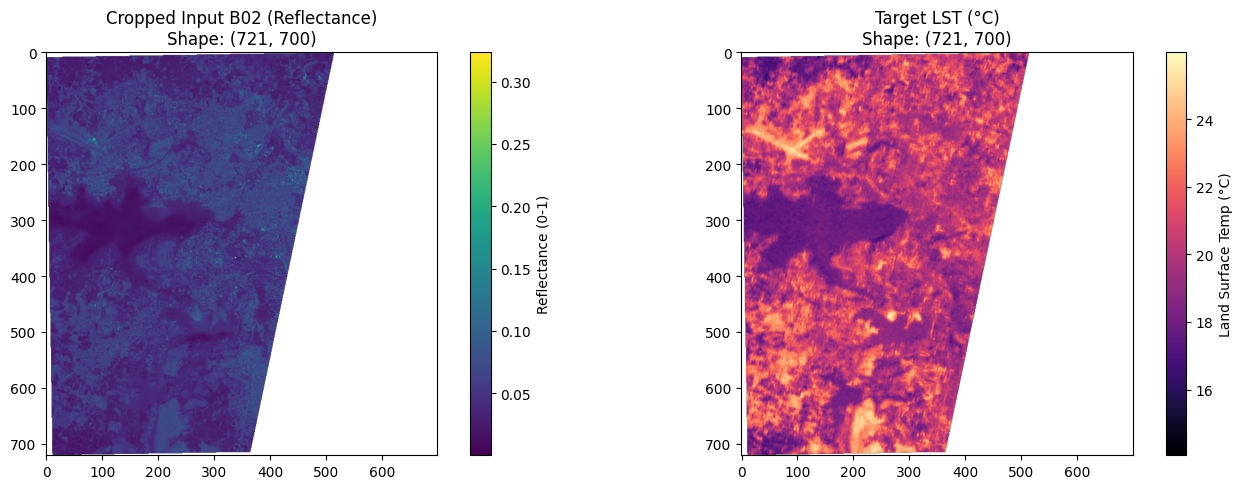

In [ ]:
import rasterio
import matplotlib.pyplot as plt
import numpy as np

input_band_path = "/content/drive/MyDrive/colab_workspace/data/hls/bhopal_ind/hls-bands/bhopal_ind.T43QGF.20250114.T052037.B02.tif"
target_lst_path = "/content/drive/MyDrive/colab_workspace/data/hls/bhopal_ind/target-lst/bhopal_ind.T43QGF.20250114.T052037.lst.tif"

with rasterio.open(input_band_path) as src_in:
    img_input = src_in.read(1).astype(float)

with rasterio.open(target_lst_path) as src_target:
    img_target = src_target.read(1).astype(float)

# ------------------------------------------------------------------
# MASK NODATA VALUES (-9999 and <= -9000)
# ------------------------------------------------------------------
img_input[img_input <= -9000] = np.nan
img_target[img_target <= -9000] = np.nan

# Scale B02 reflectance to 0-1 range if needed
if np.nanmax(img_input) > 1.0:
    img_input = img_input * 0.0001

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot B02 Reflectance
im1 = ax1.imshow(img_input, cmap="viridis")
ax1.set_title(f"Cropped Input B02 (Reflectance)\nShape: {img_input.shape}")
plt.colorbar(im1, ax=ax1, label="Reflectance (0-1)")

# Plot Target LST (°C)
im2 = ax2.imshow(img_target, cmap="magma")
ax2.set_title(f"Target LST (°C)\nShape: {img_target.shape}")
plt.colorbar(im2, ax=ax2, label="Land Surface Temp (°C)")

plt.tight_layout()
plt.show()